# 01 — Exploratory Data Analysis: Sri Lanka Paddy Yield

**Goal:** understand the dataset before modelling. That means the target, trends over time, district
differences, how weather and irrigation relate to yield, and the data-quality issues.

**Dataset:** `data_processed/paddy_dataset.csv`, built by `src/build_dataset.py` from the
Department of Census and Statistics (DCS) paddy statistics and NASA POWER weather.
See `data_processed/DATA_DICTIONARY.md`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# Chart style: thin marks, recessive grid, colour-blind-safe validated palette
SEASON_COLORS = {"Maha": "#2a78d6", "Yala": "#eb6834"}
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
DIVERGING = LinearSegmentedColormap.from_list("div", ["#eb6834", "#f0efec", "#2a78d6"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "font.size": 10, "lines.linewidth": 2, "figure.dpi": 110,
})

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

df = pd.read_csv(ROOT / "data_processed" / "paddy_dataset.csv")
print(df.shape)
df.head()

(2244, 32)


,district,season,year,yield_major,yield_minor,yield_rainfed,yield_total,sown_major,sown_minor,sown_rainfed,...,temp_min_c,humidity_pct,solar_mj_m2_day,wind_m_s,sown_share_major,sown_share_minor,sown_share_rainfed,harvest_ratio,fertilizer_shock,season_label
0,AMPARA,Yala,1981,NaN,NaN,NaN,4139.0,NaN,NaN,NaN,...,26.070,71.294,NaN,3.228,NaN,NaN,NaN,0.979884,0,1981 Yala
1,ANURADHAPURA,Yala,1981,NaN,NaN,NaN,3290.0,NaN,NaN,NaN,...,23.302,74.000,NaN,3.828,NaN,NaN,NaN,0.989755,0,1981 Yala
2,BADULLA,Yala,1981,NaN,NaN,NaN,2146.0,NaN,NaN,NaN,...,20.860,70.250,NaN,2.826,NaN,NaN,NaN,0.984178,0,1981 Yala
3,BATTICALOA,Yala,1981,NaN,NaN,NaN,2820.0,NaN,NaN,NaN,...,26.968,75.676,NaN,5.274,NaN,NaN,NaN,0.875769,0,1981 Yala
4,COLOMBO,Yala,1981,NaN,NaN,NaN,2311.0,NaN,NaN,NaN,...,24.058,84.476,NaN,3.906,NaN,NaN,NaN,0.977429,0,1981 Yala


## 1. Dataset overview

In [2]:
print("Districts:", df.district.nunique(), "| Seasons:", df.season.unique().tolist(),
      "| Years:", df.year.min(), "-", df.year.max())
print(df.groupby("season").size().rename("rows").to_string())
df.describe().T.round(1)

Districts: 27 | Seasons: ['Yala', 'Maha'] | Years: 1981 - 2025
season
Maha    1153
Yala    1091


,count,mean,std,min,25%,50%,75%,max
year,2244.0,2003.2,12.8,1981.0,1992.0,2003.0,2014.0,2025.0
yield_major,1921.0,3944.3,1191.3,0.0,3352.0,4101.0,4726.0,6958.0
yield_minor,1929.0,3337.7,984.9,0.0,2881.0,3389.0,3912.0,6272.0
yield_rainfed,1768.0,2939.9,969.5,0.0,2578.0,3041.0,3526.0,5873.0
yield_total,2244.0,3671.0,899.3,1153.0,3002.8,3601.5,4261.0,6622.0
sown_major,2103.0,9949.6,14003.0,0.0,955.5,4259.0,11926.0,66727.0
sown_minor,2103.0,4461.1,7033.0,0.0,770.0,2437.0,5064.5,53536.0
sown_rainfed,2103.0,4897.5,6727.0,0.0,109.5,2172.0,7046.0,40822.0
sown_total,2244.0,19002.8,18845.5,12.0,7130.5,12832.0,21252.2,127517.0
harvested_major,2103.0,9706.6,13787.2,0.0,908.0,4142.0,11650.5,66447.0


## 2. Missing values

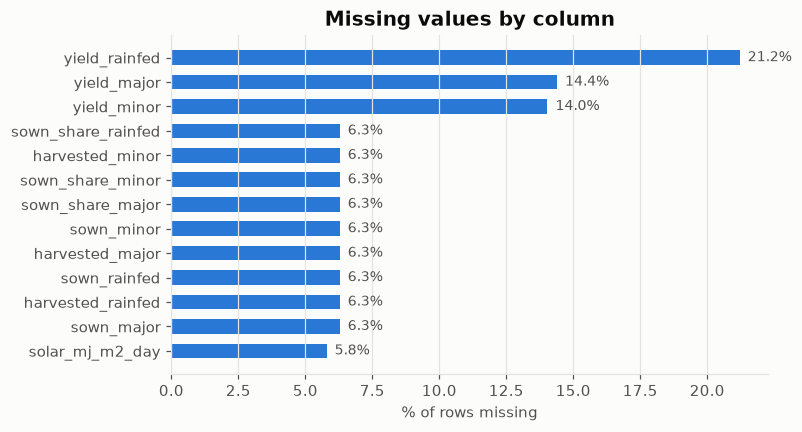

In [3]:
miss = (df.isna().mean() * 100).sort_values()
miss = miss[miss > 0]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(miss.index, miss.values, color="#2a78d6", height=0.6)
for y, v in enumerate(miss.values):
    ax.text(v + 0.3, y, f"{v:.1f}%", va="center", color=INK2, fontsize=9)
ax.set_xlabel("% of rows missing")
ax.set_title("Missing values by column")
ax.grid(axis="y", visible=False)
save(fig, "eda_01_missing_values")

Missing values come from four known causes:
- The irrigation split (`*_major/minor/rainfed`) did not exist before 1983/84.
- Solar radiation starts in 1984.
- A yield is missing for an irrigation type that a district doesn't have.
- The North has gaps during the war years. Those rows were already dropped, because they have no yield.

The target `yield_total` has no missing values.

## 3. Target: distribution of yield

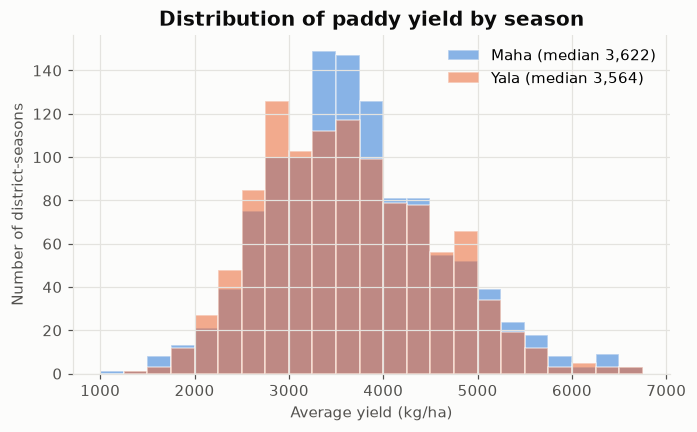

,count,mean,std,min,25%,50%,75%,max
season,,,,,,,,
Maha,1153.0,3703.0,902.0,1153.0,3085.0,3622.0,4257.0,6622.0
Yala,1091.0,3638.0,896.0,1361.0,2941.0,3564.0,4270.0,6560.0


In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
bins = np.arange(1000, 7000, 250)
for s, c in SEASON_COLORS.items():
    ax.hist(df.loc[df.season == s, "yield_total"], bins=bins, alpha=0.55, color=c,
            label=f"{s} (median {df.loc[df.season == s, 'yield_total'].median():,.0f})",
            edgecolor=SURFACE, linewidth=1)
ax.set_xlabel("Average yield (kg/ha)")
ax.set_ylabel("Number of district-seasons")
ax.set_title("Distribution of paddy yield by season")
ax.legend(frameon=False)
save(fig, "eda_02_yield_distribution")
df.groupby("season").yield_total.describe().round(0)

## 4. Yield over time (national, area-weighted)

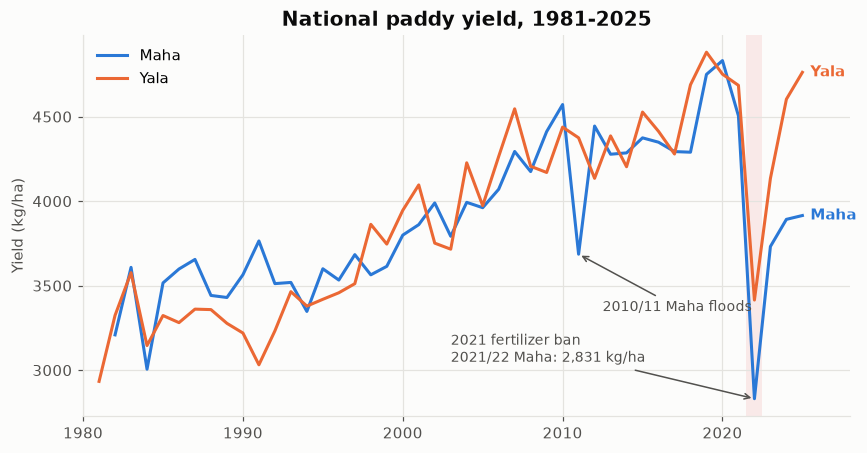

season,Maha,Yala
year,,
2018,4290.0,4689.0
2019,4750.0,4881.0
2020,4832.0,4751.0
2021,4505.0,4685.0
2022,2831.0,3415.0
2023,3732.0,4135.0
2024,3892.0,4603.0
2025,3915.0,4762.0


In [5]:
nat = (df.assign(prod=df.yield_total * df.harvested_total)
         .groupby(["season", "year"])
         .agg(prod=("prod", "sum"), area=("harvested_total", "sum")))
nat["yield"] = nat["prod"] / nat["area"]

fig, ax = plt.subplots(figsize=(9, 4.5))
for s, c in SEASON_COLORS.items():
    d = nat.loc[s]
    ax.plot(d.index, d["yield"], color=c, label=s)
    ax.text(d.index[-1] + 0.5, d["yield"].iloc[-1], s, color=c, va="center", fontweight="bold")
ax.axvspan(2021.5, 2022.5, color="#e34948", alpha=0.10, lw=0)
ax.annotate("2021 fertilizer ban\n2021/22 Maha: 2,831 kg/ha",
            xy=(2022, nat.loc[("Maha", 2022), "yield"]), xytext=(2003, 3050),
            arrowprops=dict(arrowstyle="->", color=INK2), color=INK2, fontsize=9)
ax.annotate("2010/11 Maha floods",
            xy=(2011, nat.loc[("Maha", 2011), "yield"]), xytext=(2012.5, 3350),
            arrowprops=dict(arrowstyle="->", color=INK2), color=INK2, fontsize=9)
ax.set_ylabel("Yield (kg/ha)")
ax.set_xlim(1980, 2028)
ax.set_title("National paddy yield, 1981-2025")
ax.legend(frameon=False, loc="upper left")
save(fig, "eda_03_national_trend")
nat["yield"].unstack(0).loc[2018:].round(0)

National yield rose by about **50%**, from about 3,000–3,300 kg/ha in the early 1980s to about 4,800 kg/ha in 2019–20.
That reflects improved varieties, more irrigation and more fertilizer. There is a strong upward **trend**, so `year` carries
information and the train/test split must be **by time**.

Two shocks stand out:
- **2010/11 Maha** (about 3,690 kg/ha) was hit by the January 2011 floods in the East and North-Central provinces.
- The **2021 chemical fertilizer ban** caused 2021/22 Maha to fall to **2,831 kg/ha** (−37%), the sharpest fall in 45 years.
  Yields had still not fully recovered by 2025 Maha.

## 5. Yield by district

C:\Users\Hasintha\AppData\Local\Temp\ipykernel_67244\354034798.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(data, vert=False, tick_labels=order, patch_artist=True, widths=0.6,


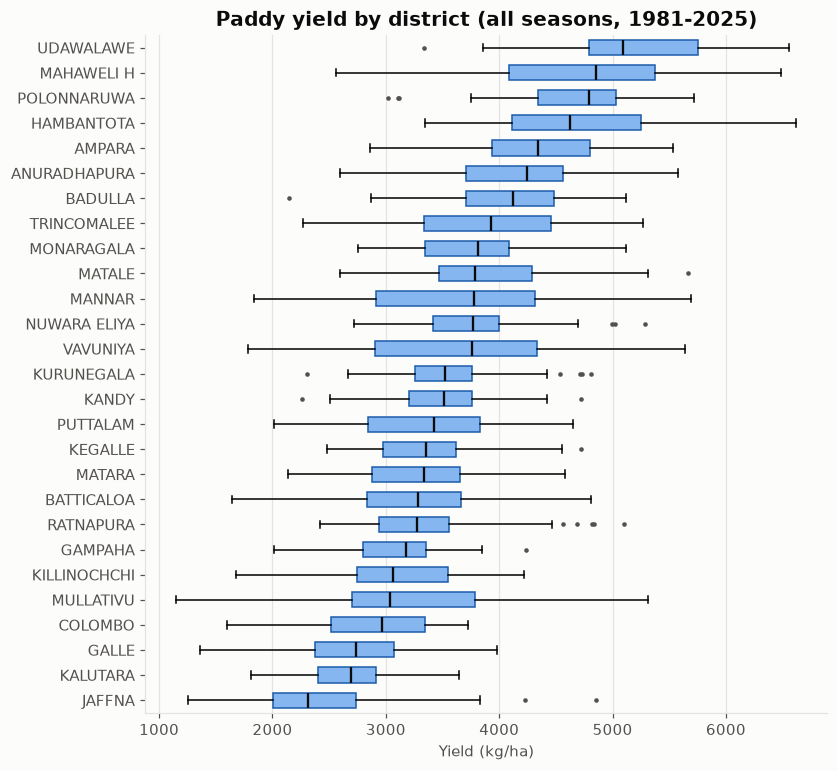

In [6]:
order = df.groupby("district").yield_total.median().sort_values().index
fig, ax = plt.subplots(figsize=(8, 8))
data = [df.loc[df.district == d, "yield_total"] for d in order]
bp = ax.boxplot(data, vert=False, tick_labels=order, patch_artist=True, widths=0.6,
                medianprops=dict(color=INK, lw=1.5), flierprops=dict(marker="o", ms=3, mfc=INK2, mec="none"))
for patch in bp["boxes"]:
    patch.set(facecolor="#86b6ef", edgecolor="#1c5cab", lw=1)
ax.set_xlabel("Yield (kg/ha)")
ax.set_title("Paddy yield by district (all seasons, 1981-2025)")
ax.grid(axis="y", visible=False)
save(fig, "eda_04_yield_by_district")

## 6. Irrigation vs yield

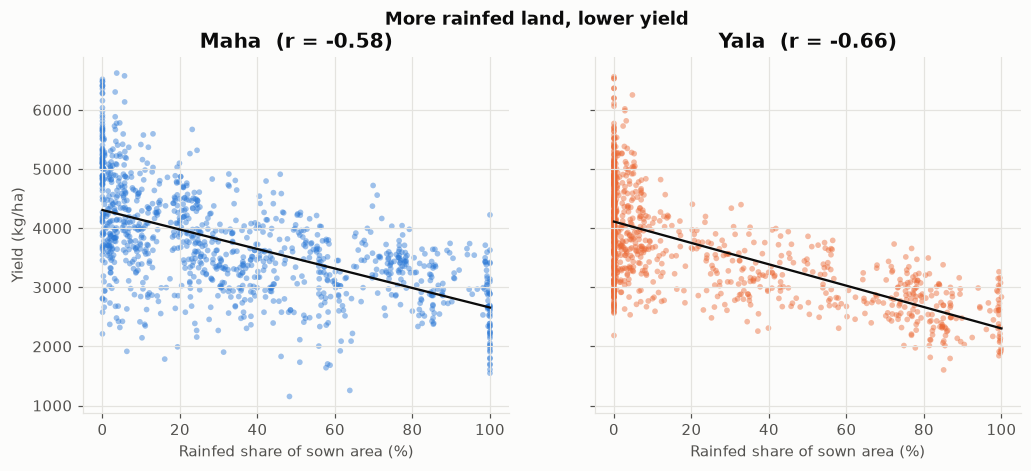

In [7]:
d = df.dropna(subset=["sown_share_rainfed"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, s in zip(axes, ["Maha", "Yala"]):
    x = d[d.season == s]
    ax.scatter(x.sown_share_rainfed * 100, x.yield_total, s=14, alpha=0.45, color=SEASON_COLORS[s], edgecolor="none")
    m, b = np.polyfit(x.sown_share_rainfed * 100, x.yield_total, 1)
    xs = np.linspace(0, 100, 50)
    ax.plot(xs, m * xs + b, color=INK, lw=1.5)
    r = x[["sown_share_rainfed", "yield_total"]].corr().iloc[0, 1]
    ax.set_title(f"{s}  (r = {r:.2f})")
    ax.set_xlabel("Rainfed share of sown area (%)")
axes[0].set_ylabel("Yield (kg/ha)")
fig.suptitle("More rainfed land, lower yield", fontweight="bold", color=INK)
save(fig, "eda_05_rainfed_share_vs_yield")

## 7. Rainfall vs yield

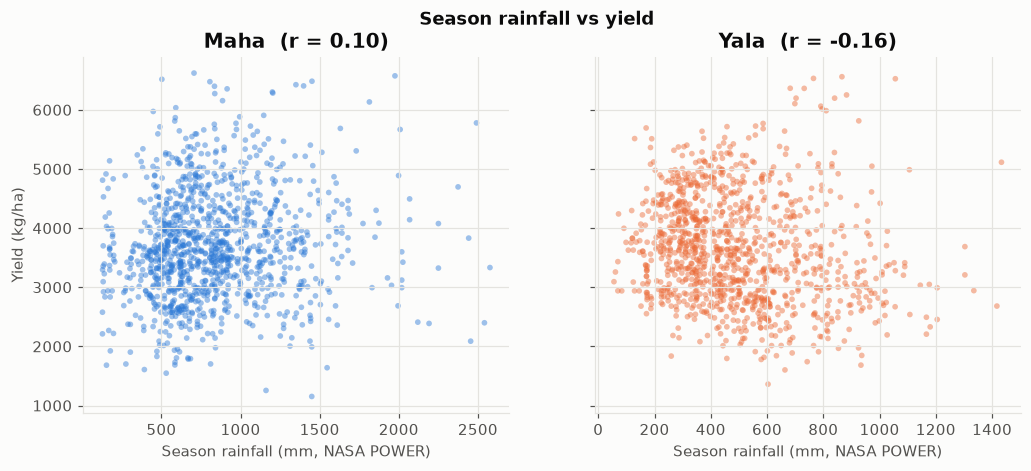

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, s in zip(axes, ["Maha", "Yala"]):
    x = df[df.season == s]
    ax.scatter(x.rain_total_mm, x.yield_total, s=14, alpha=0.45, color=SEASON_COLORS[s], edgecolor="none")
    r = x[["rain_total_mm", "yield_total"]].corr().iloc[0, 1]
    ax.set_title(f"{s}  (r = {r:.2f})")
    ax.set_xlabel("Season rainfall (mm, NASA POWER)")
axes[0].set_ylabel("Yield (kg/ha)")
fig.suptitle("Season rainfall vs yield", fontweight="bold", color=INK)
save(fig, "eda_06_rainfall_vs_yield")

Raw rainfall shows only a **weak** relationship with yield. The trend over time and the differences between
districts hide it. To see the weather effect, we look at **year-to-year changes within a district**. Below, yield
and rainfall are expressed as deviations from each district's 5-season rolling average.

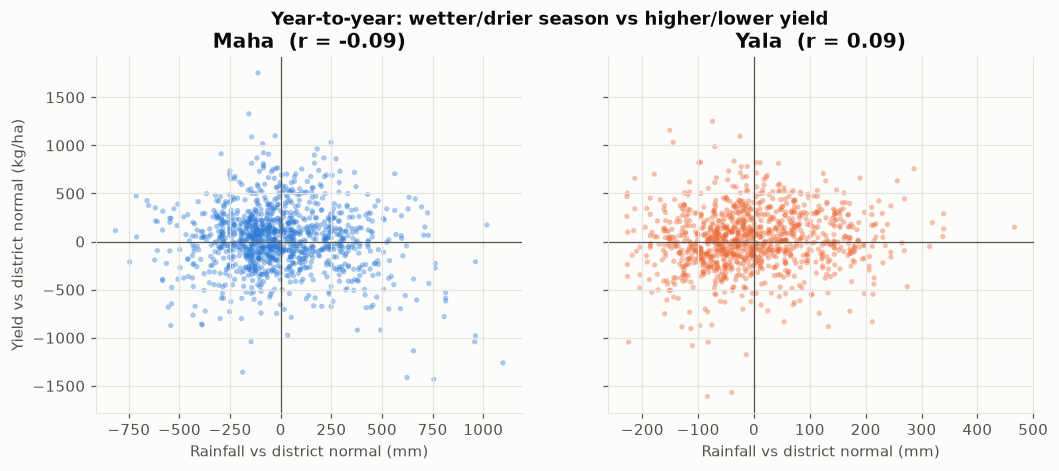

In [9]:
def detrend(g, col):
    return g[col] - g[col].rolling(5, center=True, min_periods=3).mean()

dd = df.sort_values("year").copy()
dd["yield_anom"] = dd.groupby(["district", "season"], group_keys=False).apply(lambda g: detrend(g, "yield_total"))
dd["rain_anom"] = dd.groupby(["district", "season"], group_keys=False).apply(lambda g: detrend(g, "rain_total_mm"))
dd = dd[dd.fertilizer_shock == 0].dropna(subset=["yield_anom", "rain_anom"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, s in zip(axes, ["Maha", "Yala"]):
    x = dd[dd.season == s]
    ax.scatter(x.rain_anom, x.yield_anom, s=12, alpha=0.4, color=SEASON_COLORS[s], edgecolor="none")
    r = x[["rain_anom", "yield_anom"]].corr().iloc[0, 1]
    ax.axhline(0, color=INK2, lw=0.8); ax.axvline(0, color=INK2, lw=0.8)
    ax.set_title(f"{s}  (r = {r:.2f})")
    ax.set_xlabel("Rainfall vs district normal (mm)")
axes[0].set_ylabel("Yield vs district normal (kg/ha)")
fig.suptitle("Year-to-year: wetter/drier season vs higher/lower yield", fontweight="bold", color=INK)
save(fig, "eda_07_rain_anomaly_vs_yield_anomaly")

## 8. Correlation of features with yield

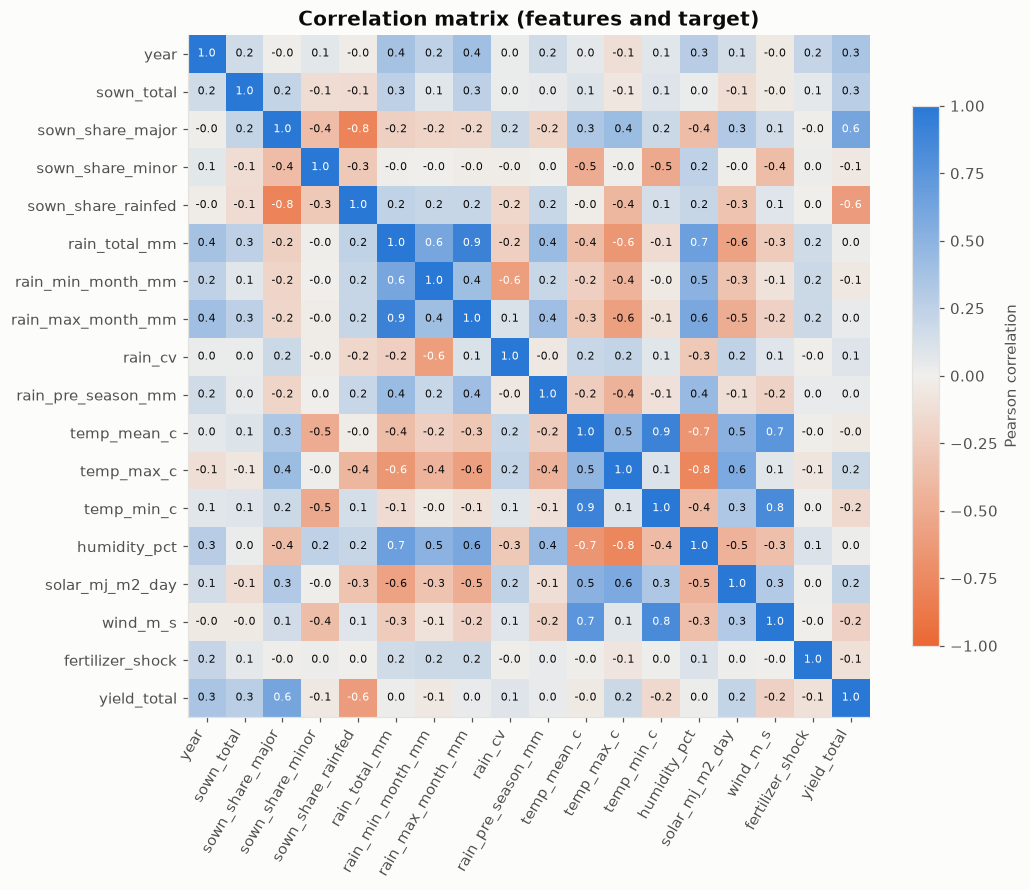

sown_share_rainfed   -0.601819
wind_m_s             -0.218409
temp_min_c           -0.162190
fertilizer_shock     -0.105685
rain_min_month_mm    -0.056506
sown_share_minor     -0.050394
temp_mean_c          -0.042875
rain_total_mm         0.021351
humidity_pct          0.022398
rain_pre_season_mm    0.035111
rain_max_month_mm     0.036791
rain_cv               0.088540
temp_max_c            0.187428
solar_mj_m2_day       0.220568
sown_total            0.268996
year                  0.347874
sown_share_major      0.615854
Name: yield_total, dtype: float64

In [10]:
features = ["year", "sown_total", "sown_share_major", "sown_share_minor", "sown_share_rainfed",
            "rain_total_mm", "rain_min_month_mm", "rain_max_month_mm", "rain_cv", "rain_pre_season_mm",
            "temp_mean_c", "temp_max_c", "temp_min_c", "humidity_pct", "solar_mj_m2_day", "wind_m_s",
            "fertilizer_shock", "yield_total"]
corr = df[features].corr()
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(features)), features, rotation=60, ha="right")
ax.set_yticks(range(len(features)), features)
for i in range(len(features)):
    for j in range(len(features)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7,
                color=INK if abs(v) < 0.6 else "white")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.75, label="Pearson correlation")
ax.set_title("Correlation matrix (features and target)")
save(fig, "eda_08_correlation_matrix")
corr["yield_total"].drop("yield_total").sort_values()

## 9. Harvest ratio (EDA only, not a model feature)

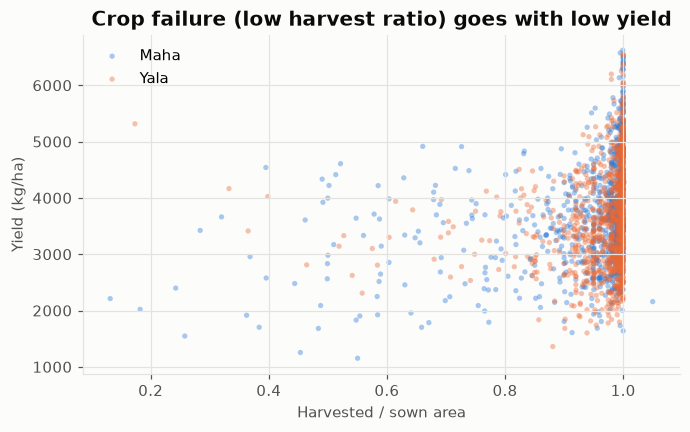

Seasons where > 20% of sown area failed: 119


In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
for s, c in SEASON_COLORS.items():
    x = df[df.season == s]
    ax.scatter(x.harvest_ratio.clip(upper=1.05), x.yield_total, s=12, alpha=0.4, color=c, edgecolor="none", label=s)
ax.set_xlabel("Harvested / sown area")
ax.set_ylabel("Yield (kg/ha)")
ax.set_title("Crop failure (low harvest ratio) goes with low yield")
ax.legend(frameon=False)
save(fig, "eda_09_harvest_ratio")
print("Seasons where > 20% of sown area failed:", (df.harvest_ratio < 0.8).sum())

`harvest_ratio` is only known **after** harvest, so it is **not** used as a feature. Using it would leak
information. It helps to show that droughts and floods destroy crops, which the weather features should capture instead.

## 10. Key findings

1. **Target.** `yield_total` is roughly bell-shaped. The mean is 3,671 kg/ha and the range is 1,153–6,622. Maha and Yala have very similar distributions.
2. **Time trend.** Yield rose about 50% between 1981 and 2020. That means:
   - `year` is useful as a trend feature.
   - The model must be tested on **future years**, not a random split. Otherwise it would look better than it really is.
3. **Shocks are visible and explainable.** The 2010/11 floods and the 2021 fertilizer ban cut 2021/22 Maha yield by 37%.
   The `fertilizer_shock` flag is therefore justified.
4. **Irrigation is the strongest single factor.**
   - The share of land under major irrigation has correlation **+0.62** with yield.
   - The rainfed share has correlation **−0.60**.
   - The highest-yielding areas are irrigated dry-zone districts: Udawalawe, Mahaweli H, Polonnaruwa, Hambantota and Ampara.
   - The lowest-yielding areas are wet-zone and northern districts: Jaffna, Kalutara, Galle and Colombo.
   - This matches agronomy. Irrigated dry-zone fields get controlled water **and** more sunshine.
     Solar radiation has correlation +0.22 with yield.
5. **Rainfall has a weak, non-linear effect.** Total rainfall alone has almost no linear correlation with yield (r = 0.02).
   - Even year-to-year changes within a district show |r| ≈ 0.09.
   - In Maha, however, **very wet seasons (more than +600 mm above normal) go with large yield losses**. That points to floods.
   - An effect like this, where the relationship isn't a straight line, suits non-linear models such as EBM and tree ensembles better than linear regression.
6. **Data quality.**
   - About 6% of rows (before 1984) lack the irrigation split and solar radiation.
   - Northern districts have war-year gaps.
   - NASA POWER weather is coarse (cells about 55 km wide).
7. **Leakage check.** `harvest_ratio`, the harvested area and the component yields are known only after harvest.
   They are **excluded** from the model features.

**Implications for modelling (notebook 02):**
- Features: district, season, year, sown area, irrigation shares, seasonal weather and the fertilizer flag.
- Split by time: train on harvest years ≤ 2017, validate on 2018–2020, test on 2021–2025. The test set includes the fertilizer shock.
- Compare **EBM** against tuned Random Forest and XGBoost.
- Metrics: RMSE, MAE and R².